# Отток клиентов банка: сегментация, SQL, проверка гипотезы и модель

**Бизнес-задача.** Банк теряет около 20% клиентов. Нужно определить, **кто именно уходит**,
насколько различаются сегменты и **на ком сосредоточить удержание**. Итог — рекомендации
и дизайн A/B-теста для проверки эффекта удерживающей меры.

**Данные.** Открытый датасет Kaggle «Bank Customer Churn» (`Customer-Churn-Records.csv`):
10 000 клиентов европейского банка (Франция, Германия, Испания), срез на один момент
времени. Это расширенная версия классического `Churn_Modelling.csv`: к исходным столбцам
добавлены `Complain`, `Satisfaction Score`, `Card Type`, `Point Earned`.

**План.**
1. Разведочный анализ: качество данных, распределения, общий отток.
2. Сегментация: отток по возрасту, стране, продуктам, активности, карте, балансу.
3. SQL: те же расчёты в SQLite и сверка с pandas.
4. Проверка гипотезы: связаны ли активность клиента и отток (хи-квадрат).
5. Модель: логистическая регрессия, отношения шансов, ROC-AUC, кривая охвата.
6. Выводы, рекомендации и дизайн A/B-теста.

In [1]:
import re
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy.stats import chi2_contingency
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportion_confint,
    proportion_effectsize,
    proportions_ztest,
)

SEED = 42
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw" / "Customer-Churn-Records.csv"
DB = ROOT / "data" / "churn.db"
SQL_FILE = ROOT / "sql" / "churn_queries.sql"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)

# Стиль графиков. Цвета: синий — основной ряд, оранжевый — второй ряд или «выше среднего».
PAL = {
    "blue": "#2a78d6", "orange": "#eb6834", "red": "#e34948",
    "ink": "#0b0b0b", "ink2": "#52514e", "muted": "#898781",
    "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb",
}
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
plt.rcParams.update({
    "figure.facecolor": PAL["surface"], "axes.facecolor": PAL["surface"],
    "savefig.facecolor": PAL["surface"], "savefig.dpi": 150, "savefig.bbox": "tight",
    "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": PAL["axis"], "axes.labelcolor": PAL["ink2"], "text.color": PAL["ink"],
    "xtick.color": PAL["muted"], "ytick.color": PAL["ink2"],
    "axes.grid": True, "grid.color": PAL["grid"], "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
PCT = mticker.PercentFormatter(1.0, decimals=0)


def save(fig, name):
    """Сохраняет график в reports/figures и выводит его."""
    fig.savefig(FIG / f"{name}.png")
    plt.show()

## 1. Разведочный анализ

### 1.1 Загрузка и качество данных

In [2]:
raw = pd.read_csv(RAW)
print("Размер:", raw.shape)
raw.head()

Размер: (10000, 18)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
quality = pd.DataFrame({
    "тип": raw.dtypes.astype(str),
    "пропусков": raw.isna().sum(),
    "уникальных": raw.nunique(),
    "min": raw.min(numeric_only=True),
    "max": raw.max(numeric_only=True),
})
print("Полных дублей строк:", raw.duplicated().sum())
print("Дублей CustomerId:  ", raw["CustomerId"].duplicated().sum())
quality

Полных дублей строк: 0
Дублей CustomerId:   0


,тип,пропусков,уникальных,min,max
Age,int64,0,70,18.00,92.00
Balance,float64,0,6382,0.00,250898.09
Card Type,str,0,4,NaN,NaN
Complain,int64,0,2,0.00,1.00
CreditScore,int64,0,460,350.00,850.00
CustomerId,int64,0,10000,15565701.00,15815690.00
EstimatedSalary,float64,0,9999,11.58,199992.48
Exited,int64,0,2,0.00,1.00
Gender,str,0,2,NaN,NaN
Geography,str,0,3,NaN,NaN


Пропусков и дублей нет. Значения проверяются на правдоподобные границы: при нарушении
`assert` останавливает выполнение ноутбука.

In [4]:
checks = {
    "возраст от 18 до 100": raw["Age"].between(18, 100).all(),
    "кредитный рейтинг от 300 до 850": raw["CreditScore"].between(300, 850).all(),
    "стаж от 0 до 10 лет": raw["Tenure"].between(0, 10).all(),
    "баланс не отрицательный": (raw["Balance"] >= 0).all(),
    "доход положительный": (raw["EstimatedSalary"] > 0).all(),
    "продуктов от 1 до 4": raw["NumOfProducts"].between(1, 4).all(),
    "бинарные поля только 0/1": raw[["HasCrCard", "IsActiveMember", "Exited", "Complain"]]
    .isin([0, 1]).all().all(),
    "оценка удовлетворённости от 1 до 5": raw["Satisfaction Score"].between(1, 5).all(),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "|", name)
assert all(checks.values()), "Есть значения вне допустимых границ"

PASS | возраст от 18 до 100
PASS | кредитный рейтинг от 300 до 850
PASS | стаж от 0 до 10 лет
PASS | баланс не отрицательный
PASS | доход положительный
PASS | продуктов от 1 до 4
PASS | бинарные поля только 0/1
PASS | оценка удовлетворённости от 1 до 5


### 1.2 Очистка

- Служебные столбцы `RowNumber` и `Surname` удалены: они не несут информации о поведении
  клиента. `CustomerId` сохранён как ключ SQL-таблицы.
- Названия столбцов переведены в `snake_case`, одинаковый для pandas и SQL.
- Добавлены производные признаки для сегментации: возрастные группы, группы по числу
  продуктов, подписи для бинарных полей.

In [5]:
AGE_ORDER = ["18-29", "30-39", "40-49", "50-59", "60+"]

df = (
    raw.drop(columns=["RowNumber", "Surname"])
    .rename(columns={
        "CustomerId": "customer_id", "CreditScore": "credit_score", "Geography": "geography",
        "Gender": "gender", "Age": "age", "Tenure": "tenure", "Balance": "balance",
        "NumOfProducts": "num_products", "HasCrCard": "has_cr_card",
        "IsActiveMember": "is_active", "EstimatedSalary": "est_salary", "Exited": "exited",
        "Complain": "complain", "Satisfaction Score": "satisfaction",
        "Card Type": "card_type", "Point Earned": "points",
    })
)
BASE_COLS = list(df.columns)  # эти столбцы уйдут в SQL-таблицу

df["age_group"] = pd.cut(df["age"], bins=[17, 29, 39, 49, 59, np.inf], labels=AGE_ORDER)
df["products_grp"] = np.where(df["num_products"] >= 3, "3-4", df["num_products"].astype(str))
df["activity"] = np.where(df["is_active"] == 1, "Активные", "Неактивные")
df["card"] = np.where(df["has_cr_card"] == 1, "Есть карта", "Нет карты")
df["balance_grp"] = np.where(df["balance"] == 0, "Нулевой", "Ненулевой")
df["geo_ru"] = df["geography"].map({"France": "Франция", "Germany": "Германия", "Spain": "Испания"})
df["gender_ru"] = df["gender"].map({"Female": "Женщины", "Male": "Мужчины"})

assert df["age_group"].notna().all()
print("После очистки:", df.shape)

После очистки: (10000, 23)


### 1.3 Общий отток

In [6]:
N = len(df)
CHURNED = int(df["exited"].sum())
BASE = df["exited"].mean()
print(f"Клиентов: {N:,}  |  ушли: {CHURNED:,}  |  отток: {BASE:.1%}".replace(",", " "))

Клиентов: 10 000  |  ушли: 2 038  |  отток: 20.4%


Каждый пятый клиент ушёл, классы несбалансированы (80/20). Accuracy в такой ситуации
неинформативна: модель, которая всегда отвечает «останется», угадает 80%. Поэтому качество
модели оценивается по ROC-AUC.

### 1.4 Чем ушедшие отличаются от оставшихся

In [7]:
num_cols = ["credit_score", "age", "tenure", "balance", "num_products", "est_salary"]
compare = df.groupby("exited")[num_cols].median().T
compare.columns = ["медиана: остались", "медиана: ушли"]
compare["среднее: остались"] = df.loc[df["exited"] == 0, num_cols].mean()
compare["среднее: ушли"] = df.loc[df["exited"] == 1, num_cols].mean()
compare.round(1)

,медиана: остались,медиана: ушли,среднее: остались,среднее: ушли
credit_score,653.0,646.0,651.8,645.4
age,36.0,45.0,37.4,44.8
tenure,5.0,5.0,5.0,4.9
balance,92063.1,109344.2,72742.8,91109.5
num_products,2.0,1.0,1.5,1.5
est_salary,99620.4,102489.3,99726.9,101509.9


Сильнее всего различается **возраст**: медиана 45 лет у ушедших против 36 у оставшихся.
Баланс у ушедших в среднем выше. Кредитный рейтинг, стаж и доход почти не отличаются.
Доход (`est_salary`) распределён почти равномерно от ~10 до 200 000 и не похож на реальные
зарплаты, что следует учитывать при интерпретации.

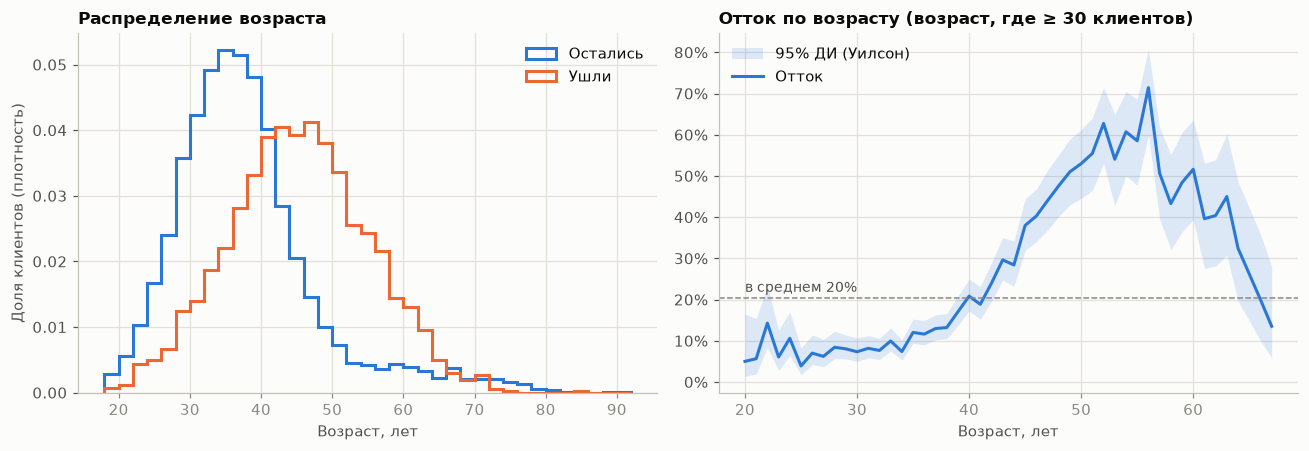

In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.2))

bins = np.arange(18, 94, 2)
for value, color, label in [(0, PAL["blue"], "Остались"), (1, PAL["orange"], "Ушли")]:
    ax1.hist(df.loc[df["exited"] == value, "age"], bins=bins, density=True,
             histtype="step", lw=2, color=color, label=label)
ax1.set_title("Распределение возраста")
ax1.set_xlabel("Возраст, лет")
ax1.set_ylabel("Доля клиентов (плотность)")
ax1.legend(loc="upper right")

by_age = df.groupby("age")["exited"].agg(clients="size", churned="sum")
by_age = by_age[by_age["clients"] >= 30]
lo, hi = proportion_confint(by_age["churned"], by_age["clients"], method="wilson")
rate = by_age["churned"] / by_age["clients"]
ax2.fill_between(by_age.index, lo, hi, color=PAL["blue"], alpha=0.15, lw=0, label="95% ДИ (Уилсон)")
ax2.plot(by_age.index, rate, color=PAL["blue"], lw=2, label="Отток")
ax2.axhline(BASE, ls="--", lw=1, color=PAL["muted"])
ax2.text(by_age.index.min(), BASE + 0.015, f"в среднем {BASE:.0%}", color=PAL["ink2"], fontsize=9)
ax2.yaxis.set_major_formatter(PCT)
ax2.set_title("Отток по возрасту (возраст, где ≥ 30 клиентов)")
ax2.set_xlabel("Возраст, лет")
ax2.legend(loc="upper left")
fig.tight_layout()
save(fig, "01_age")

До 40 лет отток держится около 5–15%, затем резко растёт и к 50–56 годам достигает 55–70%,
а после 60 снижается. Зависимость **нелинейная**, поэтому в логистическую регрессию возраст
передаётся группами, а не одним числом.

### 1.5 Подозрительный признак: `Complain`

In [9]:
complain_tab = pd.crosstab(df["complain"], df["exited"], margins=True)
complain_tab.index = ["Не жаловался", "Жаловался", "Всего"]
complain_tab.columns = ["Остались", "Ушли", "Всего"]
complain_tab["Отток"] = (complain_tab["Ушли"] / complain_tab["Всего"]).map("{:.1%}".format)
complain_tab

,Остались,Ушли,Всего,Отток
Не жаловался,7952,4,7956,0.1%
Жаловался,10,2034,2044,99.5%
Всего,7962,2038,10000,20.4%


Из 2 044 клиентов, подавших жалобу, ушли 99.5%; среди не жаловавшихся ушли только 4 из
7 956. Признак почти полностью совпадает с целевой переменной — это похоже на **утечку
данных (data leakage)**: вероятно, жалобу фиксировали в процессе ухода или после него,
и заранее предсказать уход по ней нельзя.

`complain` исключён из сегментации и модели; эффект его включения показан в разделе 5.
При этом сам факт важен: жалоба — почти гарантированный сигнал ухода, и процесс разбора
жалоб — рычаг удержания.

## 2. Сегментация

Для каждого сегмента рассчитываются:
- **отток** — доля ушедших в сегменте;
- **lift** — во сколько раз отток выше среднего по банку;
- **доля от всех ушедших** — вклад сегмента в общий отток.

Высокий отток в маленьком сегменте и умеренный отток в большом — разные задачи, поэтому
учитываются обе метрики.

In [10]:
ORDERS = {
    "age_group": AGE_ORDER,
    "geo_ru": ["Франция", "Германия", "Испания"],
    "gender_ru": ["Женщины", "Мужчины"],
    "products_grp": ["1", "2", "3-4"],
    "activity": ["Неактивные", "Активные"],
    "card": ["Нет карты", "Есть карта"],
    "balance_grp": ["Нулевой", "Ненулевой"],
}
DIMS = {
    "Возраст": "age_group", "Страна": "geo_ru", "Пол": "gender_ru",
    "Число продуктов": "products_grp", "Активность": "activity",
    "Кредитная карта": "card", "Баланс": "balance_grp",
}


def churn_by(data, col, order=None):
    """Отток, lift и вклад в общий отток по значениям столбца col."""
    t = data.groupby(col, observed=True)["exited"].agg(clients="size", churned="sum")
    if order is not None:
        t = t.reindex(order)
    t["churn_rate"] = t["churned"] / t["clients"]
    t["lift"] = t["churn_rate"] / data["exited"].mean()
    t["share_of_clients"] = t["clients"] / len(data)
    t["share_of_churned"] = t["churned"] / data["exited"].sum()
    return t


seg = pd.concat(
    {title: churn_by(df, col, ORDERS[col]) for title, col in DIMS.items()},
    names=["признак", "сегмент"],
)
seg.style.format({
    "churn_rate": "{:.1%}", "lift": "{:.2f}×",
    "share_of_clients": "{:.1%}", "share_of_churned": "{:.1%}",
}).bar(subset=["churn_rate"], color="#9ec5f4", vmin=0, vmax=1)

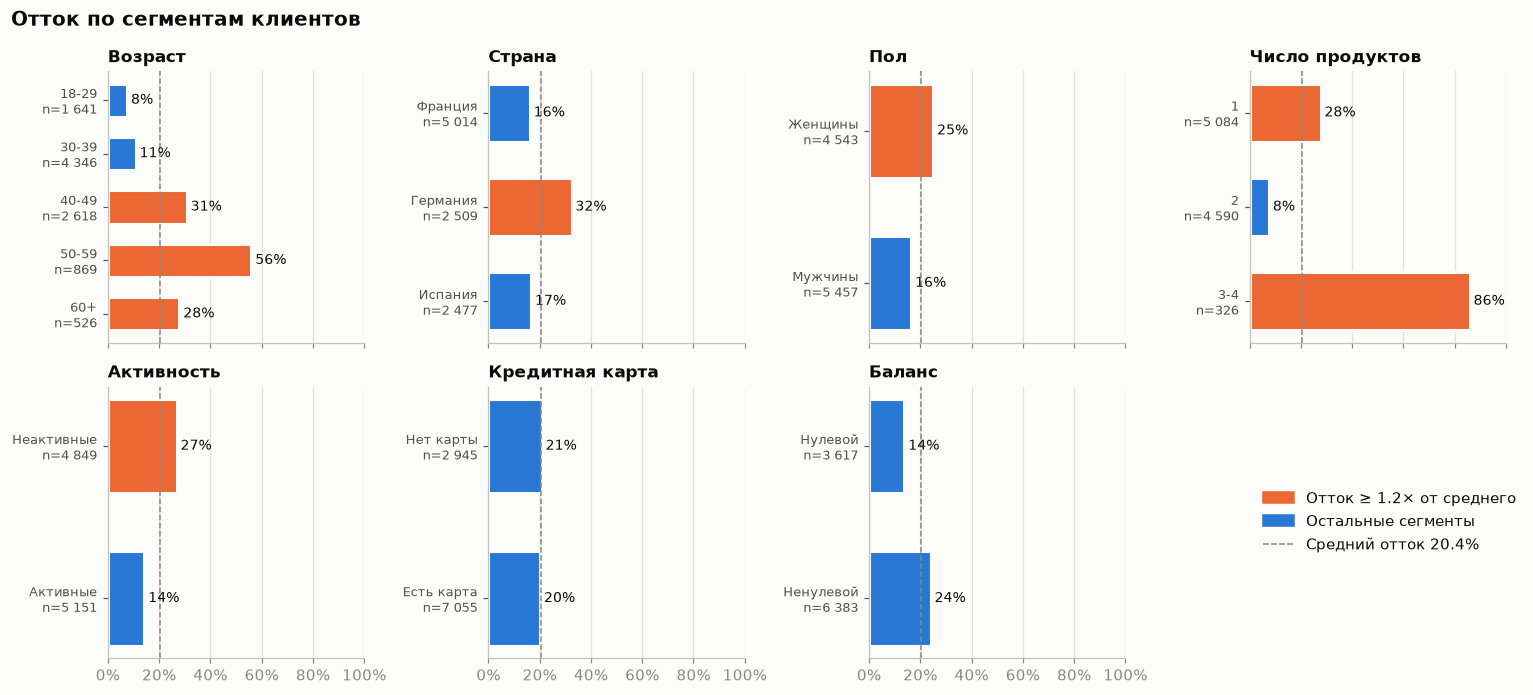

In [11]:
fig, axes = plt.subplots(2, 4, figsize=(14, 6.4), sharex=True)
for ax, (title, col) in zip(axes.flat, DIMS.items()):
    t = churn_by(df, col, ORDERS[col]).iloc[::-1]  # первый сегмент — сверху
    colors = [PAL["orange"] if x >= 1.2 else PAL["blue"] for x in t["lift"]]
    labels = [f"{idx}\nn={n:,}".replace(",", " ") for idx, n in zip(t.index, t["clients"])]
    ax.barh(labels, t["churn_rate"], height=0.62, color=colors, edgecolor=PAL["surface"], lw=2)
    for y, v in enumerate(t["churn_rate"]):
        ax.text(v + 0.015, y, f"{v:.0%}", va="center", fontsize=9, color=PAL["ink"])
    ax.axvline(BASE, ls="--", lw=1, color=PAL["muted"])
    ax.set_title(title)
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(PCT)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8.5)

legend_ax = axes.flat[-1]
legend_ax.axis("off")
legend_ax.legend(
    handles=[
        Patch(color=PAL["orange"], label="Отток ≥ 1.2× от среднего"),
        Patch(color=PAL["blue"], label="Остальные сегменты"),
        Line2D([0], [0], ls="--", lw=1, color=PAL["muted"], label=f"Средний отток {BASE:.1%}"),
    ],
    loc="center left", fontsize=10,
)
fig.suptitle("Отток по сегментам клиентов", x=0.01, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "02_segments")

**Результаты:**
- **Возраст** — один из двух самых сильных факторов: в группе 50–59 лет уходит больше
  половины клиентов (56%), в группе 18–29 — меньше 10%.
- **Германия** — отток вдвое выше, чем во Франции и Испании.
- **Неактивные** клиенты уходят почти вдвое чаще активных.
- **Число продуктов** даёт U-образную картину: с 2 продуктами отток минимальный (~8%),
  с одним — 28%, с 3–4 — больше 80%. Клиенты с 3–4 продуктами — маленький сегмент
  (326 человек), но почти все они уходят. Возможные объяснения — навязанные продукты или
  перевод средств перед уходом; по этим данным причину не определить.
- **Кредитная карта** с оттоком не связана: 20.8% против 20.2%.
- **Нулевой баланс** неожиданно связан с *меньшим* оттоком; возможная причина — страна
  (раздел 2.1).

### 2.1 Проверка на скрытый фактор: баланс и страна

In [12]:
geo_bal = (
    df.groupby(["geo_ru", "balance_grp"])["exited"]
    .agg(clients="size", churn_rate="mean")
    .unstack("balance_grp")
)
geo_bal.style.format({c: ("{:.1%}" if c[0] == "churn_rate" else "{:,.0f}") for c in geo_bal.columns},
                     na_rep="—")

В Германии **нет ни одного клиента с нулевым балансом**, и именно там самый высокий отток.
Поэтому в целом по банку нулевой баланс выглядит «защитным»: 13.8% против 24.1%, разница
10 п.п. Внутри Франции и Испании разница вдвое меньше, 4–6 п.п. Большая часть эффекта —
**смешивающий фактор (confounder)**: страна влияет и на баланс, и на отток, так что вывод
«нулевой баланс удерживает клиентов» неверен. Логистическая регрессия в разделе 5 это
подтверждает: при учёте страны баланс перестаёт быть значимым.

### 2.2 Матрица риска: возраст × страна × активность

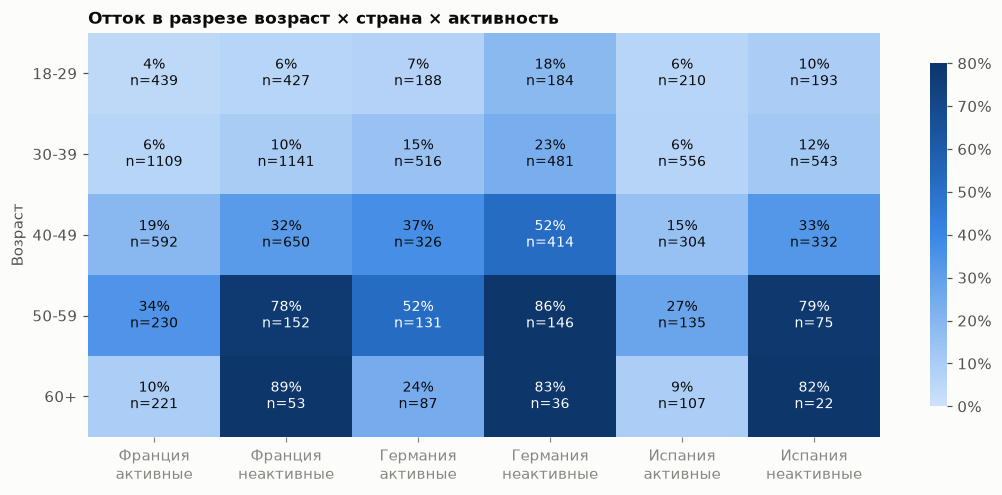

In [13]:
risk = df.groupby(["age_group", "geo_ru", "activity"], observed=True)["exited"].agg(["mean", "size"])
risk_cols = pd.MultiIndex.from_product([ORDERS["geo_ru"], ["Активные", "Неактивные"]])
rates = risk["mean"].unstack(["geo_ru", "activity"]).reindex(index=AGE_ORDER, columns=risk_cols)
sizes = risk["size"].unstack(["geo_ru", "activity"]).reindex(index=AGE_ORDER, columns=risk_cols)

cmap = LinearSegmentedColormap.from_list("blue_seq", BLUE_RAMP)
fig, ax = plt.subplots(figsize=(10, 4.6))
im = ax.imshow(rates.values, cmap=cmap, vmin=0, vmax=0.8, aspect="auto")
for i in range(rates.shape[0]):
    for j in range(rates.shape[1]):
        v, n = rates.iat[i, j], sizes.iat[i, j]
        ax.text(j, i, f"{v:.0%}\nn={n:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.4 else PAL["ink"])
ax.set_xticks(range(rates.shape[1]), [f"{g}\n{a.lower()}" for g, a in rates.columns])
ax.set_yticks(range(rates.shape[0]), rates.index)
ax.set_ylabel("Возраст")
ax.grid(False)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Отток в разрезе возраст × страна × активность")
cbar = fig.colorbar(im, ax=ax, format=PCT, shrink=0.85)
cbar.outline.set_visible(False)
fig.tight_layout()
save(fig, "03_risk_matrix")

Самые рискованные сегменты — **неактивные клиенты от 50 лет**: в каждой стране уходят
78–89% из них. Среди активных клиентов того же возраста уходят 9–52%. Во всех 15
комбинациях страны и возраста неактивные уходят чаще активных, поэтому эффект
активности не сводится к возрасту или стране. Сильнее всего разрыв после 60 лет:
активные почти не уходят (около 10%), неактивные — более чем в 80% случаев.

### 2.3 Приоритизация: размер сегмента × риск

In [14]:
segments = (
    df.groupby(["geo_ru", "age_group", "activity"], observed=True)["exited"]
    .agg(clients="size", churned="sum")
    .reset_index()
)
segments["churn_rate"] = segments["churned"] / segments["clients"]
segments["lift"] = segments["churn_rate"] / BASE
segments["share_of_churned"] = segments["churned"] / CHURNED
segments["name"] = (segments["geo_ru"] + ", " + segments["age_group"].astype(str) + ", "
                    + segments["activity"].str.lower())

top_by_rate = segments[segments["clients"] >= 100].nlargest(10, "churn_rate")
top_by_rate[["name", "clients", "churned", "churn_rate", "lift", "share_of_churned"]].style.format({
    "churn_rate": "{:.1%}", "lift": "{:.2f}×", "share_of_churned": "{:.1%}"}).hide(axis="index")

name,clients,churned,churn_rate,lift,share_of_churned
"Германия, 50-59, неактивные",146,126,86.3%,4.23×,6.2%
"Франция, 50-59, неактивные",152,118,77.6%,3.81×,5.8%
"Германия, 40-49, неактивные",414,215,51.9%,2.55×,10.5%
"Германия, 50-59, активные",131,68,51.9%,2.55×,3.3%
"Германия, 40-49, активные",326,119,36.5%,1.79×,5.8%
"Франция, 50-59, активные",230,79,34.3%,1.69×,3.9%
"Испания, 40-49, неактивные",332,110,33.1%,1.63×,5.4%
"Франция, 40-49, неактивные",650,206,31.7%,1.56×,10.1%
"Испания, 50-59, активные",135,37,27.4%,1.34×,1.8%
"Германия, 30-39, неактивные",481,113,23.5%,1.15×,5.5%


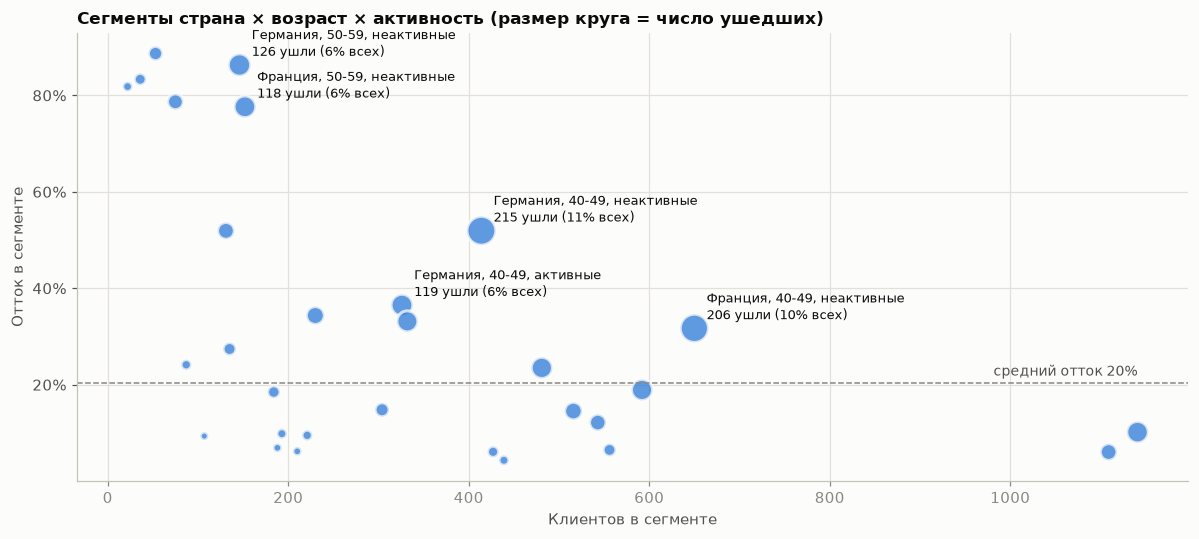

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.scatter(segments["clients"], segments["churn_rate"], s=segments["churned"] * 1.6 + 12,
           color=PAL["blue"], alpha=0.75, edgecolor=PAL["surface"], lw=2)
ax.axhline(BASE, ls="--", lw=1, color=PAL["muted"])
ax.text(segments["clients"].max(), BASE + 0.015, f"средний отток {BASE:.0%}",
        ha="right", color=PAL["ink2"], fontsize=9)
for _, r in segments.nlargest(5, "churned").iterrows():
    ax.annotate(f"{r['name']}\n{r['churned']} ушли ({r['share_of_churned']:.0%} всех)",
                (r["clients"], r["churn_rate"]), xytext=(8, 6), textcoords="offset points",
                fontsize=8.5, color=PAL["ink"])
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Клиентов в сегменте")
ax.set_ylabel("Отток в сегменте")
ax.set_title("Сегменты страна × возраст × активность (размер круга = число ушедших)")
fig.tight_layout()
save(fig, "04_segment_priority")

In [16]:
def fmt_int(x):
    """10000 -> '10 000'."""
    return f"{int(x):,}".replace(",", " ")


focus = df[(df["activity"] == "Неактивные") & (df["age"] >= 40)]
FOCUS_N, FOCUS_RATE, FOCUS_CHURNED = len(focus), focus["exited"].mean(), int(focus["exited"].sum())
print(f"Неактивные клиенты от 40 лет: {fmt_int(FOCUS_N)} клиентов ({FOCUS_N / N:.1%} базы), "
      f"отток {FOCUS_RATE:.1%} ({FOCUS_RATE / BASE:.1f}× от среднего), "
      f"на них приходится {FOCUS_CHURNED / CHURNED:.1%} всех ушедших")

Неактивные клиенты от 40 лет: 1 880 клиентов (18.8% базы), отток 49.4% (2.4× от среднего), на них приходится 45.6% всех ушедших


Для удержания выбран сегмент **«неактивные клиенты от 40 лет»**: его легко описать и найти
в CRM. Это меньше пятой части базы, но в нём уходит каждый второй клиент, и на него
приходится почти половина всех ушедших. Для этого сегмента в разделе 6 спроектирован
A/B-тест.

## 3. SQL

Ключевые расчёты повторены на SQL. Очищенная таблица загружена в SQLite (`data/churn.db`),
запросы лежат в `sql/churn_queries.sql`. В запросах используются `GROUP BY`, `CASE WHEN`,
агрегаты, условная агрегация, `HAVING`, CTE и оконная функция `RANK()`. Результаты
сверяются с pandas через `assert`.

In [17]:
con = sqlite3.connect(DB)
df[BASE_COLS].to_sql("customers", con, if_exists="replace", index=False)


def load_queries(path):
    """Разбирает .sql-файл на запросы по маркерам '-- name: <имя>'."""
    queries, name, buf = {}, None, []
    for line in path.read_text(encoding="utf-8").splitlines():
        m = re.match(r"--\s*name:\s*(\w+)", line)
        if m:
            if name:
                queries[name] = "\n".join(buf).strip()
            name, buf = m.group(1), []
        elif name:
            buf.append(line)
    if name:
        queries[name] = "\n".join(buf).strip()
    return queries


Q = load_queries(SQL_FILE)


def sql(name):
    return pd.read_sql(Q[name], con)


print("Запросов в файле:", len(Q), "|", ", ".join(Q))
sql("q01_overall")

Запросов в файле: 11 | q01_overall, q02_by_geography, q03_by_age_group, q04_by_products, q05_by_activity, q06_by_balance, q07_by_credit_card, q08_risk_matrix, q09_top_risk_segments, q10_segment_rank, q11_complain_check


,clients,churned,churn_rate_pct
0,10000,2038,20.38


In [18]:
print(Q["q03_by_age_group"])
sql("q03_by_age_group")

-- Отток по возрастным группам: группы строим через CASE WHEN
SELECT
    CASE
        WHEN age < 30 THEN '18-29'
        WHEN age < 40 THEN '30-39'
        WHEN age < 50 THEN '40-49'
        WHEN age < 60 THEN '50-59'
        ELSE '60+'
    END                             AS age_group,
    COUNT(*)                        AS clients,
    SUM(exited)                     AS churned,
    ROUND(AVG(exited) * 100, 2)     AS churn_rate_pct
FROM customers
GROUP BY age_group
ORDER BY age_group;


,age_group,clients,churned,churn_rate_pct
0,18-29,1641,124,7.56
1,30-39,4346,473,10.88
2,40-49,2618,807,30.83
3,50-59,869,487,56.04
4,60+,526,147,27.95


In [19]:
sql("q04_by_products")

,products_grp,clients,churned,churn_rate_pct
0,1,5084,1409,27.71
1,2,4590,349,7.60
2,3-4,326,280,85.89


In [20]:
sql("q08_risk_matrix")

,age_group,active_churn_pct,inactive_churn_pct,inactive_to_active_ratio
0,18-29,5.4,9.8,1.83
1,30-39,8.2,13.6,1.67
2,40-49,22.6,38.0,1.68
3,50-59,37.1,81.2,2.19
4,60+,12.5,85.6,6.83


In [21]:
sql("q09_top_risk_segments")

,geography,age_group,activity,clients,churned,churn_rate_pct,lift_vs_avg,share_of_all_churned_pct
0,Germany,50-59,inactive,146,126,86.3,4.23,6.2
1,France,50-59,inactive,152,118,77.6,3.81,5.8
2,Germany,40-49,inactive,414,215,51.9,2.55,10.5
3,Germany,50-59,active,131,68,51.9,2.55,3.3
4,Germany,40-49,active,326,119,36.5,1.79,5.8
5,France,50-59,active,230,79,34.3,1.69,3.9
6,Spain,40-49,inactive,332,110,33.1,1.63,5.4
7,France,40-49,inactive,650,206,31.7,1.56,10.1
8,Spain,50-59,active,135,37,27.4,1.34,1.8
9,Germany,30-39,inactive,481,113,23.5,1.15,5.5


In [22]:
sql("q10_segment_rank")

,geography,age_group,clients,churn_rate_pct,rank_in_country
0,France,50-59,382,51.6,1
1,France,40-49,1242,25.6,2
2,France,60+,274,24.8,3
3,France,30-39,2250,8.1,4
4,France,18-29,866,5.2,5
5,Germany,50-59,277,70.0,1
6,Germany,40-49,740,45.1,2
7,Germany,60+,123,41.5,3
8,Germany,30-39,997,18.9,4
9,Germany,18-29,372,12.6,5


**Сверка SQL и pandas.** Для каждого среза доля оттока из SQL сравнивается с расчётом
в pandas. Допуск 0.01 п.п. учитывает округление до двух знаков в SQL.

In [23]:
pairs = {
    "q02_by_geography": ("geography", "geography"),
    "q03_by_age_group": ("age_group", "age_group"),
    "q04_by_products": ("products_grp", "products_grp"),
    "q05_by_activity": ("is_active", "is_active"),
    "q06_by_balance": ("balance_grp", None),
    "q07_by_credit_card": ("has_cr_card", "has_cr_card"),
}
df["_bal_sql"] = np.where(df["balance"] == 0, "zero", "non_zero")
for qname, (sql_key, pd_key) in pairs.items():
    s = sql(qname).set_index(sql_key)["churn_rate_pct"]
    p = df.groupby(pd_key or "_bal_sql", observed=True)["exited"].mean() * 100
    s.index, p.index = s.index.astype(str), p.index.astype(str)
    diff = (s - p.reindex(s.index)).abs().max()
    assert diff <= 0.01, f"{qname}: расхождение {diff}"
    print(f"PASS | {qname:<20} максимальное расхождение {diff:.4f} п.п.")
df = df.drop(columns="_bal_sql")

ov = sql("q01_overall").iloc[0]
assert ov["clients"] == N and ov["churned"] == CHURNED
print("PASS | q01_overall          число клиентов и ушедших совпадает")

PASS | q02_by_geography     максимальное расхождение 0.0047 п.п.
PASS | q03_by_age_group     максимальное расхождение 0.0049 п.п.
PASS | q04_by_products      максимальное расхождение 0.0044 п.п.
PASS | q05_by_activity      максимальное расхождение 0.0015 п.п.
PASS | q06_by_balance       максимальное расхождение 0.0047 п.п.
PASS | q07_by_credit_card   максимальное расхождение 0.0049 п.п.
PASS | q01_overall          число клиентов и ушедших совпадает


## 4. Проверка гипотезы: активность и отток

В разделе 2 неактивные клиенты уходят почти вдвое чаще активных. Проверяется, не случайно
ли это различие.

- **H₀:** отток не зависит от активности (доли ушедших у активных и неактивных равны).
- **H₁:** отток зависит от активности (доли различаются). Проверка двусторонняя.
- **Уровень значимости:** α = 0.05.
- **Метод:** критерий хи-квадрат Пирсона на таблице сопряжённости 2×2. Обе переменные
  категориальные, наблюдения независимы (один клиент — одна строка), ожидаемые частоты
  во всех ячейках намного больше 5, поэтому условия применимости выполнены.

In [24]:
ct = pd.crosstab(df["activity"], df["exited"]).reindex(["Неактивные", "Активные"])
ct.columns = ["Остались", "Ушли"]
chi2, p_value, dof, expected = chi2_contingency(ct, correction=True)
chi2_raw, _, _, _ = chi2_contingency(ct, correction=False)

print(ct, "\n")
print("Ожидаемые частоты при H0:\n", pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(0), "\n")
print(f"χ² = {chi2:.1f} (с поправкой Йейтса), df = {dof}, p-value = {p_value:.1e}")

            Остались  Ушли
activity                  
Неактивные      3546  1303
Активные        4416   735 

Ожидаемые частоты при H0:
             Остались    Ушли
activity                    
Неактивные    3861.0   988.0
Активные      4101.0  1050.0 

χ² = 243.7 (с поправкой Йейтса), df = 1, p-value = 6.2e-55


p-значение намного меньше 0.05, поэтому **H₀ отвергается**: различие в оттоке между
активными и неактивными не объясняется случайностью.

p-значение не показывает, *насколько* велико различие, поэтому рассчитан размер эффекта:
разница долей, отношение рисков и их доверительные интервалы. Результат сверен с z-тестом
для двух долей: для таблицы 2×2 без поправки Йейтса z² = χ².

In [25]:
n_inact, n_act = ct.sum(axis=1)
k_inact, k_act = ct["Ушли"]
p_inact, p_act = k_inact / n_inact, k_act / n_act

diff_lo, diff_hi = confint_proportions_2indep(k_inact, n_inact, k_act, n_act, compare="diff", method="newcomb")
rr_lo, rr_hi = confint_proportions_2indep(k_inact, n_inact, k_act, n_act, compare="ratio", method="log")
z, p_z = proportions_ztest([k_inact, k_act], [n_inact, n_act])
cramers_v = np.sqrt(chi2_raw / ct.values.sum())

RR = p_inact / p_act
print(f"Отток неактивных: {p_inact:.1%}   активных: {p_act:.1%}")
print(f"Разница: {p_inact - p_act:+.1%}  (95% ДИ {diff_lo:+.1%} … {diff_hi:+.1%})")
print(f"Отношение рисков: {RR:.2f}×  (95% ДИ {rr_lo:.2f} … {rr_hi:.2f})")
print(f"Cramér's V = {cramers_v:.3f}")
print(f"Сверка: z² = {z**2:.1f}, χ² без поправки = {chi2_raw:.1f}")
assert np.isclose(z**2, chi2_raw)

Отток неактивных: 26.9%   активных: 14.3%
Разница: +12.6%  (95% ДИ +11.0% … +14.2%)
Отношение рисков: 1.88×  (95% ДИ 1.74 … 2.04)
Cramér's V = 0.156
Сверка: z² = 244.5, χ² без поправки = 244.5


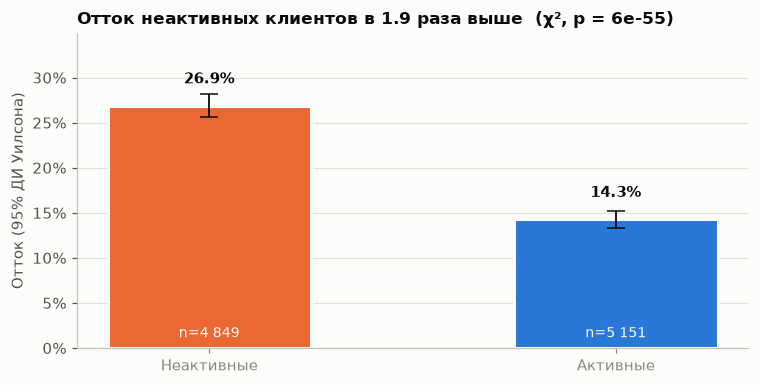

In [26]:
fig, ax = plt.subplots(figsize=(7, 3.6))
groups = ["Неактивные", "Активные"]
vals = [p_inact, p_act]
ci = proportion_confint([k_inact, k_act], [n_inact, n_act], method="wilson")
err = [np.array(vals) - ci[0], ci[1] - np.array(vals)]
ax.bar(groups, vals, width=0.5, color=[PAL["orange"], PAL["blue"]], edgecolor=PAL["surface"], lw=2)
ax.errorbar(groups, vals, yerr=err, fmt="none", ecolor=PAL["ink"], capsize=6, lw=1.2)
for x, v, n in zip(groups, vals, [n_inact, n_act]):
    ax.text(x, v + 0.025, f"{v:.1%}", ha="center", fontweight="bold")
    ax.text(x, 0.012, f"n={n:,}".replace(",", " "), ha="center", color="white", fontsize=9)
ax.yaxis.set_major_formatter(PCT)
ax.set_ylim(0, max(vals) * 1.3)
ax.grid(axis="x", visible=False)
ax.set_title(f"Отток неактивных клиентов в {RR:.1f} раза выше  (χ², p = {p_value:.0e})")
ax.set_ylabel("Отток (95% ДИ Уилсона)")
fig.tight_layout()
save(fig, "05_hypothesis_activity")

**Интерпретация.** Неактивные клиенты уходят в ~1.9 раза чаще активных; разница около
13 п.п. с узким доверительным интервалом. Cramér's V ≈ 0.16 — эффект умеренный: активность
важна, но не объясняет отток в одиночку (возраст и страна вносят не меньше).

**Ограничение:** это **связь, а не причинность**. Возможно, клиент сначала решил уйти
и поэтому перестал пользоваться банком. Снизит ли отток *реактивация*, можно проверить
только экспериментом — дизайн A/B-теста приведён в разделе 6.

### 4.1 Остальные признаки (с поправкой на множественные сравнения)

При проверке многих гипотез растёт вероятность случайно получить «значимый» результат,
поэтому p-значения скорректированы методом Холма.

In [27]:
TEST_COLS = {
    "Возраст": "age_group", "Число продуктов": "products_grp", "Страна": "geography",
    "Активность": "activity", "Пол": "gender", "Баланс (0 / не 0)": "balance_grp",
    "Кредитная карта": "card", "Стаж": "tenure", "Удовлетворённость": "satisfaction",
    "Тип карты": "card_type", "Баллы лояльности (квартили)": "points_q",
}
df["points_q"] = pd.qcut(df["points"], 4, labels=["Q1", "Q2", "Q3", "Q4"])
rows = []
for title, col in TEST_COLS.items():
    t = pd.crosstab(df[col], df["exited"])
    c2, p, d, _ = chi2_contingency(t, correction=False)
    v = np.sqrt(c2 / (t.values.sum() * (min(t.shape) - 1)))
    rows.append({"признак": title, "χ²": c2, "df": d, "p-value": p, "Cramér's V": v})
tests = pd.DataFrame(rows)
tests["p (Холм)"] = multipletests(tests["p-value"], method="holm")[1]
tests["значим при α=0.05"] = np.where(tests["p (Холм)"] < 0.05, "да", "нет")
tests.sort_values("Cramér's V", ascending=False).style.format({
    "χ²": "{:.1f}", "p-value": "{:.1e}", "p (Холм)": "{:.1e}", "Cramér's V": "{:.3f}"
}).hide(axis="index")

признак,χ²,df,p-value,Cramér's V,p (Холм),значим при α=0.05
Число продуктов,1492.5,2,0.0e+00,0.386,0.0e+00,да
Возраст,1283.5,4,1.3e-276,0.358,1.3e-275,да
Страна,300.6,2,5.2e-66,0.173,4.7e-65,да
Активность,244.5,1,4.2e-55,0.156,3.3e-54,да
Баланс (0 / не 0),150.1,1,1.6e-34,0.123,1.1e-33,да
Пол,112.9,1,2.2e-26,0.106,1.3e-25,да
Стаж,14.1,10,1.7e-01,0.037,7.5e-01,нет
Баллы лояльности (квартили),5.3,3,1.5e-01,0.023,7.5e-01,нет
Тип карты,5.1,3,1.7e-01,0.022,7.5e-01,нет
Удовлетворённость,3.8,4,4.3e-01,0.020,8.7e-01,нет


Возраст, число продуктов, страна, активность, пол и баланс значимо связаны с оттоком.
**Кредитная карта, стаж, оценка удовлетворённости, тип карты и баллы лояльности
не связаны с оттоком.** Это тоже практический вывод: на них не стоит строить
удерживающие кампании. Удовлетворённость в этом датасете, судя по всему, случайная:
отток при всех пяти оценках одинаковый, около 20%.

## 5. Модель: какие признаки сильнее всего связаны с уходом

Цель модели — не максимальная точность, а **понимание драйверов оттока** и скор для
приоритизации удержания. Поэтому используется **логистическая регрессия**: её коэффициенты
переводятся в отношения шансов (odds ratio), которые легко интерпретировать.

- Признаки: исходные поля датасета. `complain` исключён (утечка, см. 1.5); `satisfaction`,
  `card_type`, `points` исключены, так как не связаны с оттоком (см. 4.1).
- Разбиение: 75% train / 25% test со стратификацией по `exited`.
- Метрика: **ROC-AUC** — вероятность того, что модель поставит случайного ушедшего клиента
  выше случайного оставшегося; дисбаланс классов её не искажает. Устойчивость оценивается
  5-кратной кросс-валидацией на train.

In [28]:
df["credit_100"] = df["credit_score"] / 100
df["balance_10k"] = df["balance"] / 10_000
df["salary_10k"] = df["est_salary"] / 10_000
df["age_group"] = df["age_group"].astype(str)  # для формул statsmodels и OneHotEncoder

train, test = train_test_split(df, test_size=0.25, stratify=df["exited"], random_state=SEED)
print(f"train: {len(train):,}  (отток {train['exited'].mean():.1%})   "
      f"test: {len(test):,}  (отток {test['exited'].mean():.1%})".replace(",", " "))

train: 7 500  (отток 20.4%)   test: 2 500  (отток 20.4%)


### 5.1 Логистическая регрессия (statsmodels): отношения шансов

Базовые уровни для категорий: возраст 30–39, Франция, женщины, 1 продукт.
Odds ratio > 1 — признак повышает шансы ухода, < 1 — снижает.

In [29]:
FORMULA = (
    "exited ~ C(age_group, Treatment('30-39')) + C(geography, Treatment('France'))"
    " + C(gender, Treatment('Female')) + C(products_grp, Treatment('1'))"
    " + is_active + has_cr_card + credit_100 + balance_10k + salary_10k + tenure"
)
logit = smf.logit(FORMULA, data=train).fit(disp=False)

LABELS = {
    "age_group": "Возраст", "geography": "Страна", "gender": "Пол", "products_grp": "Продуктов",
    "is_active": "Активный клиент", "has_cr_card": "Есть кредитная карта",
    "credit_100": "Кредитный рейтинг, +100", "balance_10k": "Баланс, +10 тыс.",
    "salary_10k": "Доход, +10 тыс.", "tenure": "Стаж, +1 год",
}


LEVELS_RU = {"Germany": "Германия", "Spain": "Испания", "Male": "мужчины"}
REFERENCE = {"age_group": "к 30-39", "geography": "к Франции", "gender": "к женщинам",
             "products_grp": "к 1 продукту"}


def pretty(term):
    """C(age_group, Treatment('30-39'))[T.50-59] -> 'Возраст: 50-59 (к 30-39)'."""
    m = re.match(r"C\((\w+).*\)\[T\.(.+)\]", term)
    if not m:
        return LABELS.get(term, term)
    col, level = m.groups()
    return f"{LABELS[col]}: {LEVELS_RU.get(level, level)} ({REFERENCE[col]})"


ci_or = np.exp(logit.conf_int())
odds = pd.DataFrame({
    "odds_ratio": np.exp(logit.params), "ci_low": ci_or[0], "ci_high": ci_or[1],
    "p_value": logit.pvalues,
}).drop(index="Intercept")
odds.index = [pretty(i) for i in odds.index]
odds = odds.sort_values("odds_ratio")

auc_logit = roc_auc_score(test["exited"], logit.predict(test))
print(f"Pseudo R² (McFadden) = {logit.prsquared:.3f}   ROC-AUC на test = {auc_logit:.3f}")
odds.style.format({"odds_ratio": "{:.2f}", "ci_low": "{:.2f}", "ci_high": "{:.2f}", "p_value": "{:.1e}"})

Pseudo R² (McFadden) = 0.282   ROC-AUC на test = 0.852


,odds_ratio,ci_low,ci_high,p_value
Продуктов: 2 (к 1 продукту),0.22,0.19,0.26,2.3e-73
Активный клиент,0.37,0.32,0.43,3.7e-42
Пол: мужчины (к женщинам),0.61,0.53,0.69,3.5e-13
Возраст: 18-29 (к 30-39),0.67,0.52,0.86,2.0e-03
"Кредитный рейтинг, +100",0.93,0.87,1.00,4.4e-02
Есть кредитная карта,0.94,0.82,1.09,4.5e-01
"Баланс, +10 тыс.",1.00,0.98,1.01,5.2e-01
"Стаж, +1 год",1.00,0.98,1.02,9.8e-01
"Доход, +10 тыс.",1.01,1.00,1.02,1.5e-01
Страна: Испания (к Франции),1.03,0.86,1.23,7.4e-01


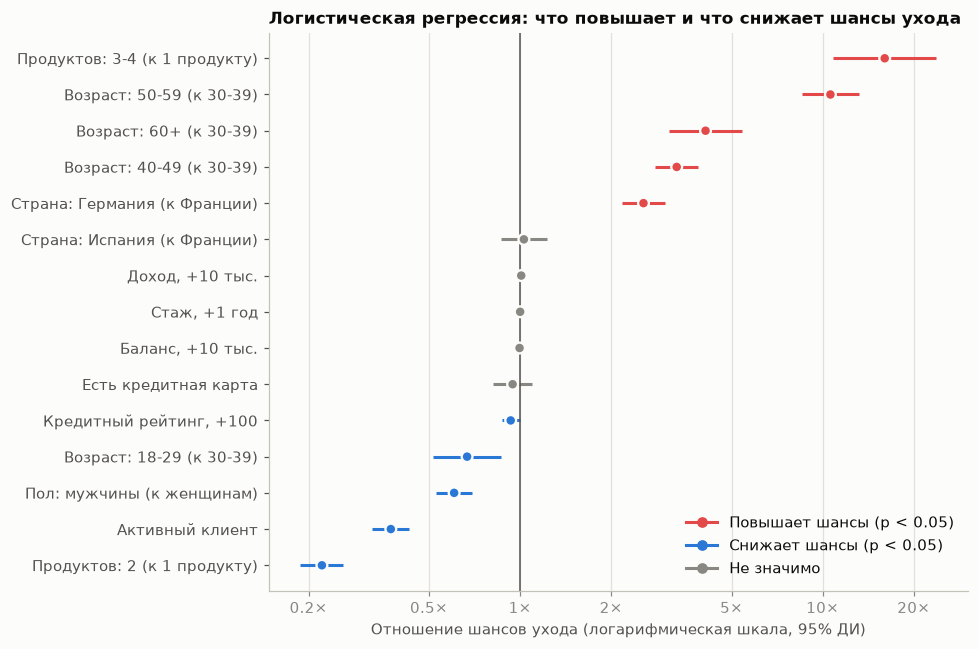

In [30]:
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(odds))
sig = odds["p_value"] < 0.05
colors = np.where(~sig, PAL["muted"], np.where(odds["odds_ratio"] > 1, PAL["red"], PAL["blue"]))
ax.hlines(y, odds["ci_low"], odds["ci_high"], color=colors, lw=2)
ax.scatter(odds["odds_ratio"], y, color=colors, s=50, zorder=3, edgecolor=PAL["surface"], lw=1.5)
ax.axvline(1, color=PAL["ink2"], lw=1)
ax.set_xscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5, 10, 20])
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.xaxis.set_minor_locator(mticker.NullLocator())
ax.set_yticks(y, odds.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Отношение шансов ухода (логарифмическая шкала, 95% ДИ)")
ax.set_title("Логистическая регрессия: что повышает и что снижает шансы ухода")
ax.legend(handles=[
    Line2D([0], [0], color=PAL["red"], marker="o", lw=2, label="Повышает шансы (p < 0.05)"),
    Line2D([0], [0], color=PAL["blue"], marker="o", lw=2, label="Снижает шансы (p < 0.05)"),
    Line2D([0], [0], color=PAL["muted"], marker="o", lw=2, label="Не значимо"),
], loc="lower right")
fig.tight_layout()
save(fig, "06_odds_ratios")

Модель подтверждает сегментацию **при прочих равных**, то есть с учётом остальных признаков:
- **3–4 продукта** — сильнейший фактор риска (шансы ухода в ~16 раз выше, чем с одним
  продуктом), **2 продукта** — сильнейший защитный фактор (шансы в ~4.5 раза ниже);
- **возраст 50–59** повышает шансы ухода примерно в 10 раз относительно 30–39;
- **активность** снижает шансы ухода почти в 3 раза (OR ≈ 0.37), даже с учётом возраста,
  страны и числа продуктов;
- **Германия** повышает шансы в ~2.5 раза, а **баланс** при учёте страны перестаёт быть
  значимым — это подтверждает вывод из 2.1;
- кредитная карта, доход и стаж не значимы.

Оговорка: odds ratio — это отношение *шансов* p/(1−p), а не вероятностей. При высоком
базовом оттоке OR заметно больше, чем отношение долей ушедших.

### 5.2 Кросс-валидация и проверка на утечку

Сравниваются два варианта логистической регрессии (scikit-learn):
1. с исходными признаками;
2. с добавленным `complain` — для демонстрации утечки.

In [31]:
LR_CAT = ["age_group", "geography", "gender", "products_grp"]
LR_NUM = ["is_active", "has_cr_card", "credit_score", "balance", "est_salary", "tenure"]


def lr_pipe(extra=()):
    prep = ColumnTransformer([
        ("cat", OneHotEncoder(drop="first"), LR_CAT),
        ("num", StandardScaler(), LR_NUM + list(extra)),
    ])
    return Pipeline([("prep", prep), ("model", LogisticRegression(max_iter=1000))])


MODELS = {
    "Логистическая регрессия": (lr_pipe(), LR_CAT + LR_NUM),
    "Лог. регрессия + complain (утечка)": (lr_pipe(extra=["complain"]), LR_CAT + LR_NUM + ["complain"]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
results, fitted = [], {}
for name, (pipe, cols) in MODELS.items():
    scores = cross_val_score(pipe, train[cols], train["exited"], cv=cv, scoring="roc_auc")
    pipe.fit(train[cols], train["exited"])
    fitted[name] = (pipe, cols)
    test_auc = roc_auc_score(test["exited"], pipe.predict_proba(test[cols])[:, 1])
    results.append({"модель": name, "CV ROC-AUC": scores.mean(), "± std": scores.std(),
                    "test ROC-AUC": test_auc})
model_cmp = pd.DataFrame(results)
model_cmp.style.format({"CV ROC-AUC": "{:.3f}", "± std": "{:.3f}", "test ROC-AUC": "{:.3f}"}).hide(axis="index")

модель,CV ROC-AUC,± std,test ROC-AUC
Логистическая регрессия,0.838,0.017,0.852
Лог. регрессия + complain (утечка),0.999,0.001,0.999


- Логистическая регрессия даёт ROC-AUC ≈ 0.84 на кросс-валидации и 0.85 на test. Разброс
  между фолдами небольшой (std ≈ 0.02), результат на test согласуется с CV — признаков
  переобучения нет.
- С `complain` ROC-AUC ≈ 1.0. Так выглядит утечка: модель «предсказывает» уход по признаку,
  который появляется вместе с уходом. Слишком высокое качество — повод искать утечку.

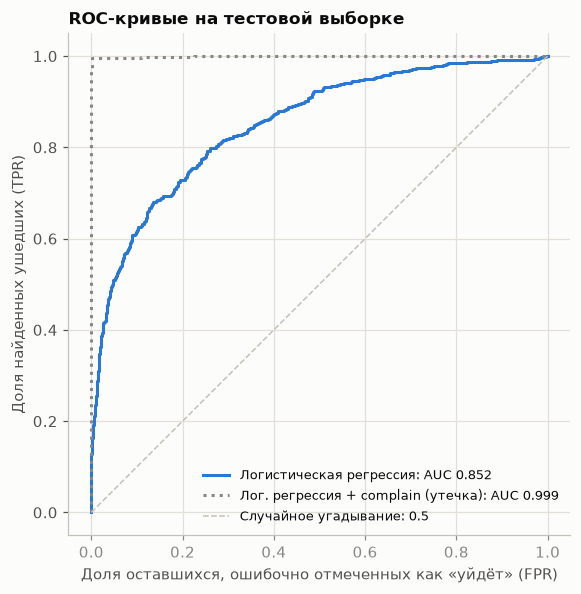

In [32]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
series = [
    ("Логистическая регрессия", PAL["blue"], "-"),
    ("Лог. регрессия + complain (утечка)", PAL["muted"], ":"),
]
for name, color, ls in series:
    pipe, cols = fitted[name]
    fpr, tpr, _ = roc_curve(test["exited"], pipe.predict_proba(test[cols])[:, 1])
    auc = roc_auc_score(test["exited"], pipe.predict_proba(test[cols])[:, 1])
    ax.plot(fpr, tpr, color=color, lw=2, ls=ls, label=f"{name}: AUC {auc:.3f}")
ax.plot([0, 1], [0, 1], color=PAL["axis"], lw=1, ls="--", label="Случайное угадывание: 0.5")
ax.set_xlabel("Доля оставшихся, ошибочно отмеченных как «уйдёт» (FPR)")
ax.set_ylabel("Доля найденных ушедших (TPR)")
ax.set_title("ROC-кривые на тестовой выборке")
ax.legend(loc="lower right", fontsize=8.5)
ax.set_aspect("equal")
fig.tight_layout()
save(fig, "07_roc")

### 5.3 Практическая ценность скора: кого обзванивать

При ограниченном бюджете удержания контакт возможен только с частью клиентов. Тестовые
клиенты упорядочены по вероятности ухода из логистической регрессии; для каждой доли
контактов рассчитан охват реально ушедших.

In [33]:
score = logit.predict(test).to_numpy()
y_true = test["exited"].to_numpy()
order = np.argsort(-score)
caught = np.cumsum(y_true[order]) / y_true.sum()
contacted = np.arange(1, len(order) + 1) / len(order)

gains = []
for share in [0.1, 0.2, 0.3, 0.5]:
    k = int(round(share * len(order)))
    gains.append({"связаться с топ-": f"{share:.0%}", "охват ушедших": caught[k - 1],
                  "доля ушедших среди выбранных (precision)": y_true[order][:k].mean(),
                  "lift": caught[k - 1] / share})
gains = pd.DataFrame(gains)
TOP20_CAUGHT = gains.loc[1, "охват ушедших"]
TOP20_PREC = gains.loc[1, "доля ушедших среди выбранных (precision)"]
gains.style.format({"охват ушедших": "{:.1%}", "доля ушедших среди выбранных (precision)": "{:.1%}",
                    "lift": "{:.2f}×"}).hide(axis="index")

связаться с топ-,охват ушедших,доля ушедших среди выбранных (precision),lift
10%,39.5%,80.4%,3.95×
20%,61.1%,62.2%,3.06×
30%,72.3%,49.1%,2.41×
50%,88.0%,35.8%,1.76×


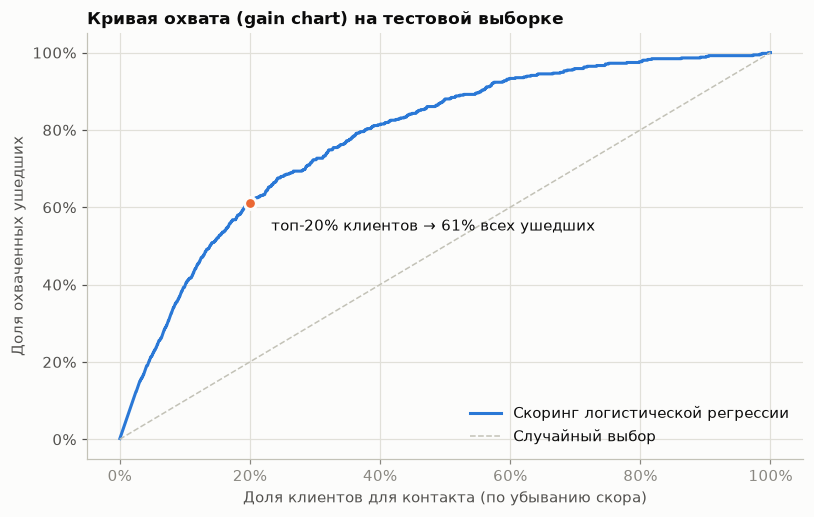

In [34]:
fig, ax = plt.subplots(figsize=(7.5, 4.8))
ax.plot(contacted, caught, color=PAL["blue"], lw=2, label="Скоринг логистической регрессии")
ax.plot([0, 1], [0, 1], color=PAL["axis"], lw=1, ls="--", label="Случайный выбор")
ax.scatter([0.2], [TOP20_CAUGHT], color=PAL["orange"], s=60, zorder=3, edgecolor=PAL["surface"], lw=2)
ax.annotate(f"топ-20% клиентов → {TOP20_CAUGHT:.0%} всех ушедших",
            (0.2, TOP20_CAUGHT), xytext=(14, -18), textcoords="offset points", fontsize=9.5)
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.set_xlabel("Доля клиентов для контакта (по убыванию скора)")
ax.set_ylabel("Доля охваченных ушедших")
ax.set_title("Кривая охвата (gain chart) на тестовой выборке")
ax.legend(loc="lower right")
fig.tight_layout()
save(fig, "08_gains")

## 6. Выводы, рекомендации и дизайн A/B-теста

### 6.1 Дизайн A/B-теста удерживающей меры

**Гипотеза.** Персональная программа реактивации для неактивных клиентов от 40 лет
(повышенный кешбэк или ставка на остаток на 3 месяца плюс звонок персонального менеджера)
снизит их отток за 90 дней.

| Элемент | Решение |
|---|---|
| Целевой сегмент | неактивные клиенты от 40 лет (см. 2.3) |
| Единица рандомизации | клиент; 50/50, стратификация по стране |
| Контроль | обычное обслуживание, без предложения |
| Тест | предложение по реактивации |
| Основная метрика | доля ушедших за 90 дней после начала теста |
| Вспомогательные | доля клиентов, ставших активными; доля оформивших второй продукт |
| Защитные (guardrail) | стоимость удержания одного клиента, число жалоб, отписки от коммуникаций |
| Статистика | z-тест для двух долей (или χ²), α = 0.05, мощность 80%, двусторонняя проверка |
| Длительность | фиксированная: набор выборки + 90 дней наблюдения, без промежуточных «подглядываний» |
| Проверки | SRM (соотношение групп ≈ 50/50), A/A-проверка сплита до старта |
| Решение | внедрение, если отток значимо ниже и выручка от удержанных клиентов превышает стоимость программы |

**Размер выборки.** Базовый уровень оттока взят по сегменту; для нескольких значений MDE
(минимального детектируемого эффекта) рассчитано необходимое число клиентов в группе.

In [35]:
power = NormalIndPower()
p0 = FOCUS_RATE
rows = []
for mde in [0.03, 0.05, 0.07, 0.10]:
    h = abs(proportion_effectsize(p0, p0 - mde))
    n_group = power.solve_power(effect_size=h, alpha=0.05, power=0.8, ratio=1, alternative="two-sided")
    rows.append({"MDE, п.п.": f"−{mde * 100:.0f}", "отток: контроль → тест": f"{p0:.1%} → {p0 - mde:.1%}",
                 "относительное снижение": f"{mde / p0:.0%}", "клиентов в группе": int(np.ceil(n_group)),
                 "всего в тесте": int(np.ceil(n_group)) * 2})
sample_size = pd.DataFrame(rows)

# Какой эффект можно заметить, если взять весь сегмент из этого датасета (по половине в группу)
h_avail = power.solve_power(nobs1=FOCUS_N / 2, alpha=0.05, power=0.8, ratio=1, alternative="two-sided")
p1_avail = np.sin(np.arcsin(np.sqrt(p0)) - h_avail / 2) ** 2
MDE_AVAIL = p0 - p1_avail
print(f"Базовый отток в сегменте: {p0:.1%}")
print(f"Если весь сегмент ({fmt_int(FOCUS_N)} клиентов) разделить пополам, "
      f"MDE ≈ {MDE_AVAIL * 100:.1f} п.п.")
sample_size.style.hide(axis="index")

Базовый отток в сегменте: 49.4%
Если весь сегмент (1 880 клиентов) разделить пополам, MDE ≈ 6.4 п.п.


"MDE, п.п.",отток: контроль → тест,относительное снижение,клиентов в группе,всего в тесте
−3,49.4% → 46.4%,6%,4352,8704
−5,49.4% → 44.4%,10%,1563,3126
−7,49.4% → 42.4%,14%,795,1590
−10,49.4% → 39.4%,20%,387,774


Сегмент такого размера, как в выборке (1 880 клиентов на 10 000), позволяет заметить
снижение оттока не меньше чем на ~6.4 п.п. (с 49% до 43%). В реальном банке с
миллионами клиентов сегмент будет на порядки больше, и можно ловить эффект в 2–3 п.п.
MDE стоит выбирать от экономики: эффект должен окупать стоимость программы удержания.

**Как оценить результат.** Разница долей оттока с 95% доверительным интервалом;
z-тест для двух долей; проверка SRM; расчёт экономики: «удержано дополнительно»
= n_тест × (p_контроль − p_тест), сравнить с затратами на программу.

In [36]:
con.close()
summary = {
    "клиентов": N,
    "отток, %": round(BASE * 100, 1),
    "отток неактивных, %": round(p_inact * 100, 1),
    "отток активных, %": round(p_act * 100, 1),
    "во сколько раз неактивные уходят чаще": round(RR, 2),
    "p-value (χ²)": f"{p_value:.1e}",
    "отток 50–59 лет, %": round(seg.loc[("Возраст", "50-59"), "churn_rate"] * 100, 1),
    "отток в Германии, %": round(seg.loc[("Страна", "Германия"), "churn_rate"] * 100, 1),
    "отток с 2 продуктами, %": round(seg.loc[("Число продуктов", "2"), "churn_rate"] * 100, 1),
    "отток с 1 продуктом, %": round(seg.loc[("Число продуктов", "1"), "churn_rate"] * 100, 1),
    "отток с 3–4 продуктами, %": round(seg.loc[("Число продуктов", "3-4"), "churn_rate"] * 100, 1),
    "сегмент «неактивные 40+»: клиентов": FOCUS_N,
    "сегмент «неактивные 40+»: отток, %": round(FOCUS_RATE * 100, 1),
    "сегмент «неактивные 40+»: доля всех ушедших, %": round(FOCUS_CHURNED / CHURNED * 100, 1),
    "ROC-AUC лог. регрессии (test)": round(auc_logit, 3),
    "топ-20% по скору: охват ушедших, %": round(TOP20_CAUGHT * 100, 1),
    "топ-20% по скору: precision, %": round(TOP20_PREC * 100, 1),
    "MDE на сегменте из датасета, п.п.": round(MDE_AVAIL * 100, 1),
}
pd.Series(summary, name="значение").to_frame()

,значение
клиентов,10000
"отток, %",20.4
"отток неактивных, %",26.9
"отток активных, %",14.3
во сколько раз неактивные уходят чаще,1.88
p-value (χ²),6.2e-55
"отток 50–59 лет, %",56.0
"отток в Германии, %",32.4
"отток с 2 продуктами, %",7.6
"отток с 1 продуктом, %",27.7


### 6.2 Итоги

**Ключевые цифры**
- Отток по банку — **20.4%** (2 038 из 10 000 клиентов).
- **Неактивные клиенты уходят в 1.9 раза чаще активных**: 26.9% против 14.3%
  (χ² = 244, p ≈ 6·10⁻⁵⁵; разница 12.6 п.п., 95% ДИ 11.0–14.2 п.п.).
- Клиенты **50–59 лет** уходят в 56% случаев, это в 2.7 раза чаще среднего.
  До 40 лет отток 8–11%.
- **Германия** — 32.4% оттока против ~16% во Франции и Испании.
- **Число продуктов**: 2 продукта — 7.6% оттока, 1 продукт — 27.7%, 3–4 продукта — 85.9%.
- **Неактивные клиенты от 40 лет** — 19% базы, но **46% всех ушедших** (отток 49%).
- Логистическая регрессия: **ROC-AUC 0.85**. Топ-20% клиентов по скору охватывают
  **61% ушедших** — втрое лучше случайного выбора.
- С оттоком **не связаны**: кредитная карта, тип карты, стаж, удовлетворённость, баллы.

**Рекомендации**

| Приоритет | Что делать | Почему | Как проверить |
|---|---|---|---|
| P0 | Программа реактивации для неактивных клиентов от 40 лет | 19% базы дают 46% оттока; на активность банк может влиять напрямую | A/B-тест из 6.1 |
| P0 | Ежемесячный скоринг риска ухода и проактивный контакт с топ-20% | охватывает 61% будущих ушедших при контакте с пятой частью базы | A/B: контакт по скору vs контроль |
| P1 | Кросс-селл второго продукта клиентам с одним продуктом, без навязывания третьего и четвёртого | 1 продукт — 28% оттока, 2 — 8%, а 3–4 — 86% | A/B-тест: связь может быть не причинной |
| P1 | Исследовать причины оттока в Германии | шансы ухода в 2.6 раза выше при прочих равных | интервью с ушедшими, сравнение условий конкурентов, CJM |
| P1 | Разобраться, когда фиксируется жалоба, и сделать её триггером удержания | 99.5% подавших жалобу ушли | если жалоба появляется до ухода — A/B-тест быстрой реакции на жалобу |
| — | Не тратить бюджет удержания на кредитные карты и тип карты | связи с оттоком нет (p > 0.7 после поправки Холма) | — |

**Ограничения**
- Данные — срез на один момент. Нет истории, неизвестно, за какой период считается уход,
  и не видно, что менялось у клиента перед уходом.
- Все выводы — о **связи, а не о причинах**. Причинность проверяется только экспериментом.
- `Complain` похож на утечку. `Satisfaction Score`, `Card Type`, `Point Earned` никак
  не связаны с оттоком, а `EstimatedSalary` распределён равномерно. Похоже, эти поля
  сгенерированы синтетически.
- Один европейский банк и три страны: напрямую на другой рынок выводы не переносятся.

**Развитие.** На данных банка модель можно дополнить поведенческими признаками
(транзакции и входы в приложение за последние 3 месяца) и прогнозировать уход в ближайшие
90 дней, а клиентов приоритизировать по ожидаемым потерям (вероятность ухода × ценность
клиента), а не только по вероятности ухода.